In [1]:
%pip install numpy matplotlib seaborn pylatexenc "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import math
import random
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution

In [3]:
depth_A = 6
depth_B = 3
num_of_elements = 16

In [4]:
dataset = [
    [random.randint(0, 255) for _ in range(4)] for _ in range(num_of_elements)
]
query_index = random.randint(0, len(dataset) - 1)
query = dataset[query_index]

In [5]:
dataset

[[21, 253, 107, 222],
 [116, 210, 70, 177],
 [220, 173, 186, 220],
 [138, 197, 177, 145],
 [30, 231, 19, 177],
 [84, 203, 59, 250],
 [175, 234, 184, 34],
 [30, 184, 186, 82],
 [126, 214, 159, 129],
 [204, 65, 167, 222],
 [150, 100, 117, 154],
 [177, 172, 156, 238],
 [125, 28, 76, 123],
 [230, 28, 38, 55],
 [130, 107, 156, 131],
 [100, 213, 201, 229]]

In [6]:
query_index

3

In [7]:
query

[138, 197, 177, 145]

In [8]:
import numpy as np

D = np.asarray(dataset, dtype=float)
q = np.asarray(query, dtype=float)

D = D / np.linalg.norm(D, axis=1, keepdims=True)
q = q / np.linalg.norm(q)

overlaps = D @ q
scores = overlaps ** 2

print("Query index:", query_index)
print("Ideal overlap scores:", scores)
print("Highest-scoring index:", np.argmax(scores))
print("Score of selected query:", scores[query_index])

Query index: 3
Ideal overlap scores: [0.78200405 0.88115963 0.93980469 1.         0.65345154 0.76708724
 0.87496745 0.86580949 0.99149491 0.77808655 0.90369267 0.92749942
 0.71049106 0.42121791 0.95249037 0.9496182 ]
Highest-scoring index: 3
Score of selected query: 1.0


### **<u>PART 1: APPROXIMATE AMPLITUDE ENCODING USING PARAMETERIZED QUANTUM CIRCUIT</u>**

Step 1. Calculate number of required qubits

Step 2. Prepare target state (normzalition, padding) -> O(N_I * N_D)

Step 3. Prepare gaussian kernel and hadamard for the given dataset shape -> O((2^ceil(log(N_I))) * (2^ceil(log(N_D)))) ≈ O(N_I * N_D)

Step 4. Randomly initialize a list of theta for the Ry layers of the parameterized quantum circuit -> O(depth * log() + log())

Step 5. Define the objective function which is to minimize the loss (MMD)

Step 6. Prepare parameterized quantum circuit using the Ry and CNOT gates in a single layer for a given number of layers/depth of the circuit

Step 7. Calculate the final state from the circuit

Step 8. Calculate loss (MMD between the measured state and the target state)

Step 9. Calculate gradients (parameter shift rule) and update the parameters using adam optimizer

Step 10. Repeat until loss minimized or max epochs reached


In [ ]:
class ApproximateAmplitudeEncoder:
    # used to generate operation A and B
    # A is the unitary operation used to approximately encode the dataset
    # B is the unitary operation used to approximately encode the query

    def __init__(self):
        self.rng = np.random.default_rng(42)

    def hadamard(self, n):  # Time complexity ≈ O(N_D * N_I)
        """Generate the Hadamard matrix of size 2^n x 2^n."""
        H_base = np.array([
            [1.0, 1.0],
            [1.0, -1.0]
        ]) / np.sqrt(2)

        H = np.array([[1.0]])

        for _ in range(n):  # number of iterations = O(2^(ceil(log(N_D)))*2^(ceil(log(N_I)))) ≈ O(N_D * N_I)
            H = np.kron(H, H_base)  # kronecker product or tensor product --> matrix size grows exponentially

        print("\nShape of Hadamard matrix:", H.shape)

        return H

    def gaussian_kernel(self, N):    # Time complexity ≈ O(N^2)
        """Compute the Gaussian kernel between each pair of indices.
        It is used in MMD loss function.
        """

        x = np.arange(N) # gives an array of indices from 0 to N-1  --> O(N)
        pairwise_differences = x[:, None] - x[None, :]  # compute pairwise differences --> O(N^2)

        kernel_matrix = np.exp(-64 * pairwise_differences ** 2) # O(N^2)

        # approximately gives an identity matrix, but with some off-diagonal elements
        # kernel assigns high similarlity to indices that are close to each other,
        # and low similarity to indices that are far apart

        print("\nShape of Gaussian kernel matrix:", kernel_matrix.shape)
        print("Gaussian kernel matrix:", kernel_matrix)

        return kernel_matrix

    def mmd_loss(self, P, Q, kernel): # Time complexity = O(N^2)
        """ MMD^2(P, Q) = P^T K P + Q^T K Q - 2 P^T K Q """
        loss = (P @ kernel @ P) + (Q @ kernel @ Q) - (2 * P @ kernel @ Q) # O(N^2) for matrix-vector multiplications

        return loss

    def cost_function(self, parameters, target_amplitudes, kernel, H, depth, n_qubits):
        """
        Calculate L = (L1 + L2) / 2.

        L1 compares computational-basis probabilities.
        L2 compares probabilities after a Hadamard transform.
        """
        qc = self.pqc(parameters, depth, n_qubits)
        state = Statevector.from_instruction(qc)
        amplitudes = np.real_if_close(state.data).real

        # L1: compare computational-basis probabilities.
        probability_1 = np.abs(amplitudes) ** 2
        target_probability_1 = np.abs(target_amplitudes) ** 2

        L1 = self.mmd_loss(
            probability_1,
            target_probability_1,
            kernel
        )

        # L2: compare probabilities after applying H to every qubit.
        transformed_amplitudes = H @ amplitudes
        target_transformed_amplitudes = H @ target_amplitudes

        probability_2 = np.abs(transformed_amplitudes) ** 2
        target_probability_2 = np.abs(target_transformed_amplitudes) ** 2

        L2 = self.mmd_loss(
            probability_2,
            target_probability_2,
            kernel
        )

        assert np.isclose(probability_1.sum(), 1.0)
        assert np.isclose(target_probability_1.sum(), 1.0)
        assert np.isclose(probability_2.sum(), 1.0)
        assert np.isclose(target_probability_2.sum(), 1.0)

        return (L1 + L2) / 2


    def parameter_shift_gradient(self, parameters, target, kernel, H, depth, n_qubits):
        """Calculate the MMD loss gradient using the parameter-shift rule."""

        target_p = np.abs(target) ** 2
        target_h = np.abs(H @ target) ** 2

        circuit = self.pqc(parameters, depth, n_qubits)
        amplitudes = Statevector.from_instruction(circuit).data
        prob = np.abs(amplitudes) ** 2
        prob_h = np.abs(H @ amplitudes) ** 2

        grad = np.zeros_like(parameters)
        shift = np.pi / 2

        for i in range(len(parameters)):    # O(depth * n_qubits)
            plus = parameters.copy()
            minus = parameters.copy()
            plus[i] += shift
            minus[i] -= shift

            state_plus = Statevector.from_instruction(self.pqc(plus, depth, n_qubits)).data
            state_minus = Statevector.from_instruction(self.pqc(minus, depth, n_qubits)).data

            prob_plus = np.abs(state_plus) ** 2
            prob_minus = np.abs(state_minus) ** 2

            prob_plus_h = np.abs(H @ state_plus) ** 2
            prob_minus_h = np.abs(H @ state_minus) ** 2

            der_prob = (prob_plus - prob_minus) / 2
            der_prob_h = (prob_plus_h - prob_minus_h) / 2

            grad[i] = (der_prob @ (kernel @ (prob - target_p))
                + der_prob_h @ (kernel @ (prob_h - target_h)))

        return grad

    def adam_optimizer(self, objective, initial_parameters, target, kernel, H,
                   depth, n_qubits, epochs, learning_rate=0.1):
        parameters = initial_parameters.copy()
        m = np.zeros_like(parameters) # creates an array of zeros with the same shape as parameters
        v = np.zeros_like(parameters)
        beta1, beta2 = 0.9, 0.999
        epsilon = 1e-8
        loss_history = []

        patience = 10 # number of epochs to wait for improvement before stopping
        min_delta = 1e-6 # minimum change in the loss to qualify as an improvement
        best_loss = float("inf") # initialized to infinity
        wait = 0

        for epoch in range(1, epochs + 1):
            gradient = self.parameter_shift_gradient(parameters, target, kernel, H, depth, n_qubits)

            m = beta1 * m + (1 - beta1) * gradient
            v = beta2 * v + (1 - beta2) * gradient**2

            m_hat = m / (1 - beta1**epoch)
            v_hat = v / (1 - beta2**epoch)

            lr = learning_rate if epoch <= 100 else 0.01
            parameters -= lr * m_hat / (np.sqrt(v_hat) + epsilon)

            loss = objective(parameters)
            loss_history.append(loss)

            if loss < best_loss - min_delta:
                best_loss = loss
                best_parameters = parameters.copy()
                wait = 0
            else:
                wait += 1

            # early stopping if the loss does not improve for a certain number of epochs

            # if wait >= patience:
            #     print(f"Early stopping at epoch {epoch}")
            #     break

        plt.plot(range(1, len(loss_history) + 1), loss_history)
        plt.xlabel("Epoch")
        plt.ylabel("MMD Loss")
        plt.title("Adam Training Loss")
        plt.grid(True)
        plt.show()

        return best_parameters, best_loss

    def pqc(self, parameters, depth, n_qubits):
        qc = QuantumCircuit(n_qubits)
        t = 0

        for _ in range(depth):
            # rotation layer
            for q in range(n_qubits):
                qc.ry(parameters[t], q)
                t += 1

            # entangling layer
            for q in range(n_qubits - 1):
                qc.cx(q, q + 1)

        return qc

    def train_circuit(self, target_amplitudes, depth, epochs, label):
        """Train a parameterized circuit to approximate a target state."""

        target_amplitudes = np.asarray(target_amplitudes, dtype=float)

        n_qubits = int(round(math.log2(len(target_amplitudes))))

        num_parameters = depth * n_qubits
        initial_parameters = self.rng.uniform(-np.pi, np.pi, num_parameters)

        H = self.hadamard(n_qubits)
        kernel = self.gaussian_kernel(len(target_amplitudes))

        def objective(parameters):
            loss = self.cost_function(
                parameters, target_amplitudes,
                kernel, H, depth, n_qubits
            )
            return loss


        trained_parameters, final_loss = self.adam_optimizer(
            objective, initial_parameters, target_amplitudes,
            kernel, H, depth, n_qubits, epochs
        )

        trained_circuit = self.pqc(
            trained_parameters, depth, n_qubits
        )
        state = Statevector.from_instruction(trained_circuit)
        print(f"\nFinal statevector: {state.data}")

        print(f"\n{label} training finished")
        print(f"Number of qubits: {n_qubits}")
        print(f"Circuit depth (layers): {depth}")
        print(f"Number of parameters: {num_parameters}")
        print(f"Final MMD loss: {final_loss:.8f}")

        return trained_parameters, trained_circuit

    def generate_A(self, dataset, depth=6, epochs=500):
        """Find the parameters of the layers to approximate the dataset using a parameterized quantum circuit."""
        dataset = np.array(dataset, dtype=float, copy=True)
        N_I, N_D = dataset.shape
        n_index_q = math.ceil(math.log2(N_I))
        n_data_q = math.ceil(math.log2(N_D))
        total_qubits = n_index_q + n_data_q
        padded_N_I = 2 ** n_index_q
        padded_N_D = 2 ** n_data_q
        print(f"\nNumber of index qubits: {n_index_q}")
        print(f"Number of data qubits: {n_data_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of index states: {padded_N_I}")
        print(f"Padded number of data states: {padded_N_D}")
        print("Total number of states:", padded_N_I * padded_N_D)

        # create target

        print(f"\nOriginal dataset: {dataset}")

        norms = np.linalg.norm(dataset, axis=1, keepdims=True)
        if np.any(norms == 0):
            raise ValueError("A database row has zero norm; handle it explicitly.")
        normalized_dataset = dataset / norms

        target = np.zeros(padded_N_I * padded_N_D, dtype=float)
        for i in range(N_I):
            for j in range(N_D):
                target[i * padded_N_D + j] = (normalized_dataset[i, j] / np.sqrt(N_I))
        print(f"\nTarget: {target}")

        target_norm = np.linalg.norm(target)
        if not np.isclose(target_norm, 1.0):
            raise ValueError(f"Database target is not normalized: {target_norm}")

        # train and minimize cost function

        parameters, circuit = self.train_circuit(target, depth, epochs, label="A (database)")

        display(circuit.draw("mpl"))
        self.plot_distribution(target, circuit)

        fidelity = np.abs(np.vdot(target, Statevector.from_instruction(circuit).data)) ** 2
        print(f"\nFidelity between target and encoded state: {fidelity:.8f}")

        # return the parameters
        return parameters

    def generate_B(self, query, depth=3, epochs=300):
        """Find the parameters of the layers to approximate the query using a parameterized quantum circuit."""
        query = np.array(query, dtype=float, copy=True)

        N_Q = len(query)
        n_query_q = math.ceil(math.log2(N_Q))
        total_qubits = n_query_q
        padded_N_Q = 2 ** n_query_q
        print(f"\nNumber of query qubits: {n_query_q}")
        print(f"Total number of qubits: {total_qubits}")
        print(f"Padded number of query states: {padded_N_Q}")

        # create target

        print(f"\nOriginal query: {query}")

        norm = np.linalg.norm(query)
        if norm == 0:
            raise ValueError("Query has zero norm; it cannot be amplitude encoded.")

        query = query / norm

        target = np.zeros(padded_N_Q, dtype=float)
        target[:N_Q] = query

        if not np.isclose(np.linalg.norm(target), 1.0):
            raise ValueError("Query target is not normalized.")

        print(f"\nTarget: {target}")

        # train and minimize cost function

        parameters, circuit = self.train_circuit(target, depth, epochs, label="B (query)")

        display(circuit.draw("mpl"))
        self.plot_distribution(target, circuit)

        fidelity = np.abs(np.vdot(target, Statevector.from_instruction(circuit).data)) ** 2
        print(f"\nFidelity between target and encoded state: {fidelity:.8f}")

        # return the parameters
        return parameters

    def plot_distribution(self, target, circuit):
        original = np.abs(target) ** 2
        encoded = Statevector.from_instruction(circuit).probabilities()

        plt.plot(original, "o-", label="Target")
        plt.plot(encoded, "x-", label="Encoded")
        plt.xlabel("State index")
        plt.ylabel("Probability")
        plt.legend()
        plt.show()


Number of index qubits: 4
Number of data qubits: 2
Total number of qubits: 6
Padded number of index states: 16
Padded number of data states: 4
Total number of states: 64

Original dataset: [[ 21. 253. 107. 222.]
 [116. 210.  70. 177.]
 [220. 173. 186. 220.]
 [138. 197. 177. 145.]
 [ 30. 231.  19. 177.]
 [ 84. 203.  59. 250.]
 [175. 234. 184.  34.]
 [ 30. 184. 186.  82.]
 [126. 214. 159. 129.]
 [204.  65. 167. 222.]
 [150. 100. 117. 154.]
 [177. 172. 156. 238.]
 [125.  28.  76. 123.]
 [230.  28.  38.  55.]
 [130. 107. 156. 131.]
 [100. 213. 201. 229.]]

Target: [0.01483838 0.17876721 0.0756051  0.15686292 0.09469593 0.17143228
 0.05714409 0.14449293 0.13693418 0.10768006 0.11577162 0.13693418
 0.10392368 0.14835481 0.13329341 0.10919517 0.02558208 0.19698199
 0.01620198 0.15093425 0.06212963 0.15014661 0.04363867 0.18490962
 0.12608907 0.1685991  0.13257365 0.0244973  0.02719177 0.16677617
 0.16858895 0.07432416 0.09786857 0.16622123 0.12350082 0.10019878
 0.14540954 0.04633147 0.11903

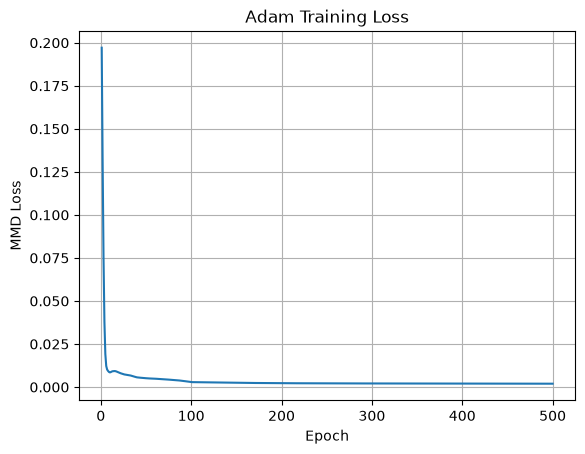


Final statevector: [ 0.06974186+0.j  0.16392154+0.j  0.1060431 +0.j  0.12893208+0.j
  0.10656296+0.j  0.12822757+0.j  0.08445124+0.j  0.1568981 +0.j
 -0.10698528+0.j  0.11989693+0.j  0.11679061+0.j  0.12081891+0.j
 -0.0645472 +0.j  0.17324804+0.j  0.1033525 +0.j  0.13033969+0.j
  0.07863312+0.j  0.19220935+0.j  0.10662713+0.j  0.11338332+0.j
  0.05230166+0.j  0.1347277 +0.j  0.08896714+0.j  0.15083947+0.j
  0.12412361+0.j  0.15506924+0.j  0.13519929+0.j  0.11906207+0.j
  0.08161527+0.j  0.13288161+0.j  0.12706029+0.j  0.13305013+0.j
  0.08563098+0.j  0.16647406+0.j  0.09814329+0.j  0.11575983+0.j
  0.12335801+0.j  0.1188793 +0.j  0.12194236+0.j  0.15745152+0.j
  0.14219783+0.j  0.10897005+0.j  0.11373423+0.j  0.13185019+0.j
  0.12606411+0.j  0.1226441 +0.j  0.14703378+0.j  0.13617167+0.j
  0.13364034+0.j  0.10086106+0.j  0.08212544+0.j  0.16222437+0.j
  0.24001883+0.j  0.07047953+0.j  0.04272353+0.j  0.03031358+0.j
  0.14953052+0.j  0.10610282+0.j  0.14059473+0.j  0.12855739+0.j
  0.0

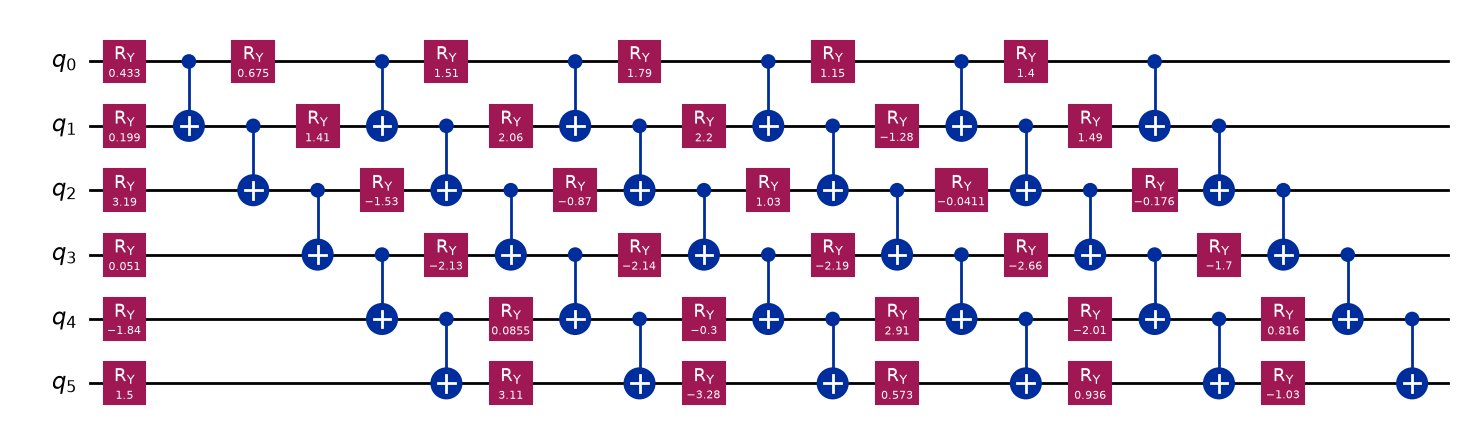

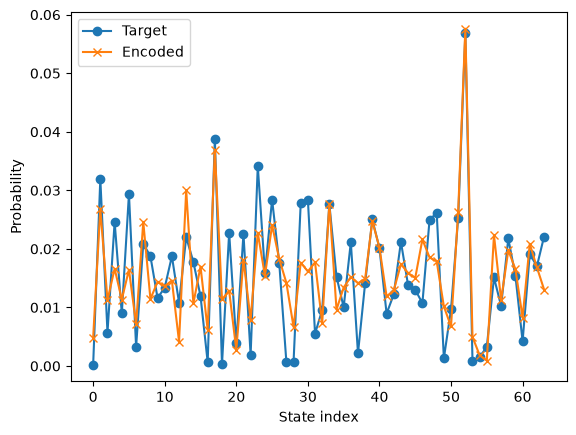


Fidelity between target and encoded state: 0.85322913


In [10]:
encoder = ApproximateAmplitudeEncoder()
A_parameters = encoder.generate_A(dataset, depth_A)


Number of query qubits: 2
Total number of qubits: 2
Padded number of query states: 4

Original query: [138. 197. 177. 145.]

Target: [0.41569471 0.59341926 0.53317365 0.43678067]

Shape of Hadamard matrix: (4, 4)

Shape of Gaussian kernel matrix: (4, 4)
Gaussian kernel matrix: [[1.00000000e+000 1.60381089e-028 6.61626106e-112 7.02066780e-251]
 [1.60381089e-028 1.00000000e+000 1.60381089e-028 6.61626106e-112]
 [6.61626106e-112 1.60381089e-028 1.00000000e+000 1.60381089e-028]
 [7.02066780e-251 6.61626106e-112 1.60381089e-028 1.00000000e+000]]


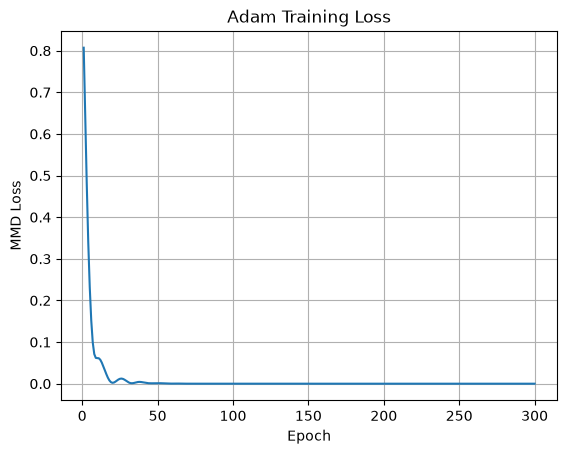


Final statevector: [-0.41487698+0.j -0.5931035 +0.j -0.5335068 +0.j -0.43757952+0.j]

B (query) training finished
Number of qubits: 2
Circuit depth (layers): 3
Number of parameters: 6
Final MMD loss: 0.00000061


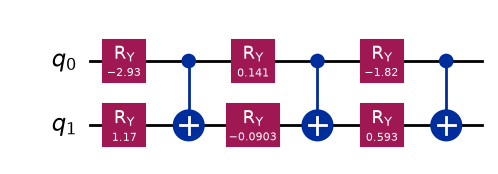

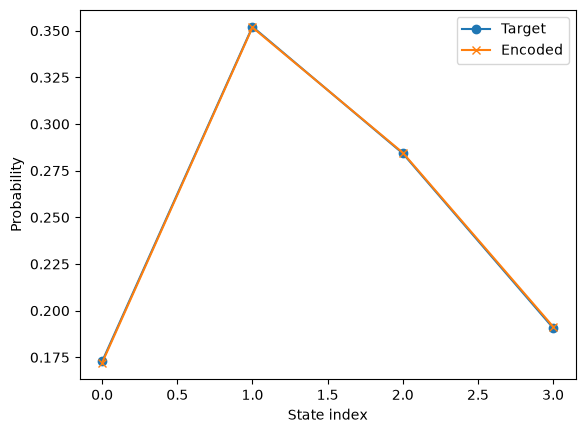


Fidelity between target and encoded state: 0.99999848


In [11]:
B_parameters = encoder.generate_B(query, depth_B)

### **<u>PART 2: UTILIZE GROVER SEARCH FOR IMAGE MATCHING</u>**

![image.png](attachment:image.png)

In [12]:
class GroverSearch:
  def pqc(self, parameters, depth, n_qubits):
    qc = QuantumCircuit(n_qubits)
    t = 0

    for _ in range(depth):
        # rotation layer
        for q in range(n_qubits):
            qc.ry(parameters[t], q)
            t += 1

        # entangling layer
        for q in range(n_qubits - 1):
            qc.cx(q, q + 1)

    return qc

  def build_U(self):
    # U = (B† ⊗ I_I) A
    # Qubit order: |data>|index>
    # A encodes the database, B† acts on data qubits only

    qc = QuantumCircuit(self.total_qubits)

    A = self.pqc(self.A_parameters, self.depth_A, self.total_qubits)
    B = self.pqc(self.B_parameters, self.depth_B, self.n_data_q)

    qc.compose(A, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    qc.compose(B.inverse(), qubits=self.data_q, inplace=True)
    qc.barrier()

    return qc

  def phase_flip_zero(self, qc, qubits):
    # Phase flip of |00...0>
    # X gates convert |00...0> into |11...1>
    # H-MCX-H implements the multi-controlled Z operation to flip the phase of |11...1>

    if len(qubits) == 1:
        qc.x(qubits[0])
        qc.z(qubits[0])
        qc.x(qubits[0])

    else:
        qc.x(qubits)

        qc.h(qubits[-1])
        qc.mcx(qubits[:-1], qubits[-1])
        qc.h(qubits[-1])

        qc.x(qubits)

    return qc

  def oracle(self): # inversion-test oracle Go
    # Go phase-flips the all-zero data state after B†
    # This makes the phase depend on the query-data overlap

    qc = QuantumCircuit(self.total_qubits)

    self.phase_flip_zero(qc, self.data_q)
    qc.barrier()

    return qc

  def diffuser(self): # Gd = U† (phase flip of zero on all qubits) U
    # implements reflection about U|0>

    qc = QuantumCircuit(self.total_qubits)

    U = self.build_U()

    qc.compose(U.inverse(), qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    self.phase_flip_zero(qc, list(range(self.total_qubits)))
    qc.barrier()

    qc.compose(U, qubits=list(range(self.total_qubits)), inplace=True)
    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10

    state = Statevector.from_instruction(qc)
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()} # convert binary string keys to integers for better readability
    print(f"{text}: ", probs_dict)

    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))

    display(plot)

  def run(self, dataset, query,
      A_parameters, B_parameters, depth_A=6, depth_B=3,
      num_of_iter=1, no_of_shots=2000
  ):
    # initialize the qubits

    self.N_I = len(dataset) # number of rows
    self.N_D = len(dataset[0])  # number of features
    self.N_Q = len(query) # number of features in query

    self.n_index_q = math.ceil(math.log2(self.N_I))
    self.n_data_q = math.ceil(math.log2(self.N_D))

    self.padded_N_I = 2 ** self.n_index_q
    self.padded_N_D = 2 ** self.n_data_q

    self.index_q = list(range(self.n_data_q, self.n_data_q + self.n_index_q))
    self.data_q = list(range(self.n_data_q))

    self.total_qubits = self.n_index_q + self.n_data_q

    # pad the dataset and query to the power of 2

    padded_dataset = np.zeros((self.padded_N_I, self.padded_N_D))
    padded_dataset[:self.N_I, :self.N_D] = dataset
    dataset = padded_dataset

    padded_query = np.zeros(self.padded_N_D)
    padded_query[:self.N_Q] = query
    query = padded_query

    # A and B parameters

    self.A_parameters = np.asarray(A_parameters)
    self.B_parameters = np.asarray(B_parameters)
    self.depth_A = depth_A
    self.depth_B = depth_B

    print("N = ", self.N_I)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Total no of qubits = ", self.total_qubits)

    # num_of_iter = max(1, round(((math.pi / 4) * math.sqrt(self.N_I)) - 0.5))
    # print("\nGrover iterations: ", num_of_iter)

    index_qubits = QuantumRegister(self.n_index_q, name="index")
    data_qubits = QuantumRegister(self.n_data_q, name="data")
    qc = QuantumCircuit(index_qubits, data_qubits)

    qc = self.build_U()
    self.visualize(qc, "Encoded state U|Psi(0)>")

    for iteration in range(num_of_iter):
        print(f"\nGROVER ITERATION {iteration + 1}")

        print("\nOracle: ")
        oracle_circuit = self.oracle()
        qc.compose(oracle_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Oracle output")

        print("\nDiffuser: ")
        diffuser_circuit = self.diffuser()
        qc.compose(diffuser_circuit, qubits=list(range(self.total_qubits)), inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()

    classical_register = ClassicalRegister(self.n_index_q, name="index_result")
    self.qc.add_register(classical_register)

    self.qc.measure(self.index_q, classical_register)

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)

    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

  def draw_circuit(self):
    display(self.qc.draw("mpl"))

  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size (N):", self.N_I)
    print("Index qubits:", len(self.index_q))
    print("Data qubits:", len(self.data_q))
    print("Total qubits:", self.qc.num_qubits)
    print("Classical bits:", self.qc.num_clbits)

    print("\nCIRCUIT ANALYSIS")

    print("Circuit width:", self.qc.width())
    print("Circuit size:", self.qc.size())
    print("Circuit depth/layers:", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

  def visualize_probability(self, qc, text):
    state = Statevector.from_instruction(qc)
    amplitudes = state.data

    # The data qubits are the least-significant qubits.
    # Each index k has a block of padded_N_D amplitudes.
    joint_probs = np.array([
        abs(amplitudes[k * self.padded_N_D]) ** 2
        for k in range(self.padded_N_I)
    ])

    # Probability that the data register is NOT all zeros
    total_success = joint_probs.sum()
    p_others = 1.0 - total_success

    print(f"\n{text}")
    print("P(index=k AND data=00):", joint_probs)
    print("Others (projection failure):", p_others)
    print("Total probability:", total_success + p_others)

    plt.bar(range(self.padded_N_I), joint_probs)
    plt.xlabel("Database index")
    plt.ylabel("Joint probability")
    plt.title(text)
    plt.show()

N =  16
Index qubits =  [2, 3, 4, 5]
Data qubits =  [0, 1]
Total no of qubits =  6
Encoded state U|Psi(0)>:  {0: np.float64(0.05960281894629346), 1: np.float64(0.05954699819747938), 2: np.float64(0.05405837797266951), 3: np.float64(0.06185139726476871), 4: np.float64(0.06735272410325902), 5: np.float64(0.05155471419180792), 6: np.float64(0.07190776667853704), 7: np.float64(0.058165227940965236), 8: np.float64(0.05807872096440701), 9: np.float64(0.06901040382078355), 10: np.float64(0.06241464293110468), 11: np.float64(0.0710953931253795), 12: np.float64(0.061094026508666785), 13: np.float64(0.06532061538651794), 14: np.float64(0.06991106356571947), 15: np.float64(0.059035108401640904)}


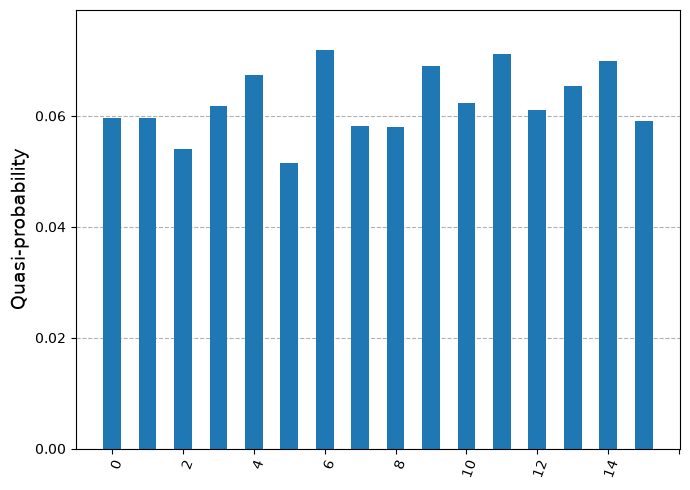


GROVER ITERATION 1

Oracle: 
Oracle output:  {0: np.float64(0.059602818946293434), 1: np.float64(0.05954699819747935), 2: np.float64(0.054058377972669484), 3: np.float64(0.061851397264768695), 4: np.float64(0.06735272410325897), 5: np.float64(0.051554714191807904), 6: np.float64(0.071907766678537), 7: np.float64(0.05816522794096522), 8: np.float64(0.058078720964407), 9: np.float64(0.06901040382078352), 10: np.float64(0.06241464293110466), 11: np.float64(0.07109539312537948), 12: np.float64(0.061094026508666764), 13: np.float64(0.06532061538651793), 14: np.float64(0.06991106356571944), 15: np.float64(0.059035108401640876)}


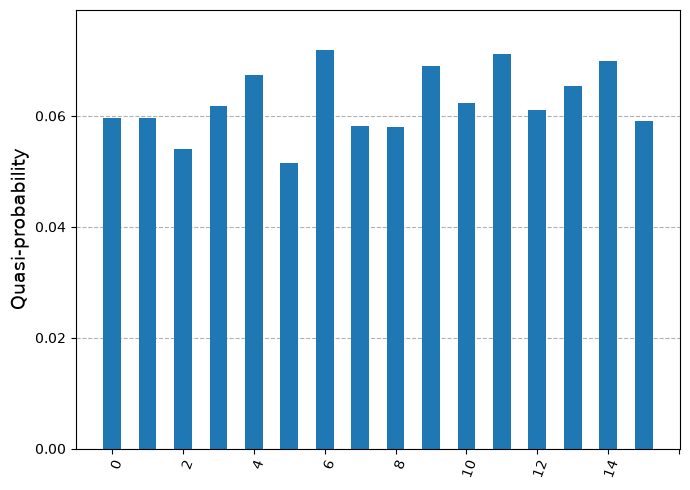


Diffuser: 
Diffuser output:  {0: np.float64(0.02663550544053923), 1: np.float64(0.04059149251059334), 2: np.float64(0.20939228327527942), 3: np.float64(0.16743216715470366), 4: np.float64(0.03335221780651832), 5: np.float64(0.04178971889654723), 6: np.float64(0.016597762727228467), 7: np.float64(0.019249886949968303), 8: np.float64(0.022625611460569975), 9: np.float64(0.035902481860537495), 10: np.float64(0.03564049665569219), 11: np.float64(0.026015369531978902), 12: np.float64(0.06053072644805167), 13: np.float64(0.2112662878758994), 14: np.float64(0.039591691148272275), 15: np.float64(0.01338630025761084)}


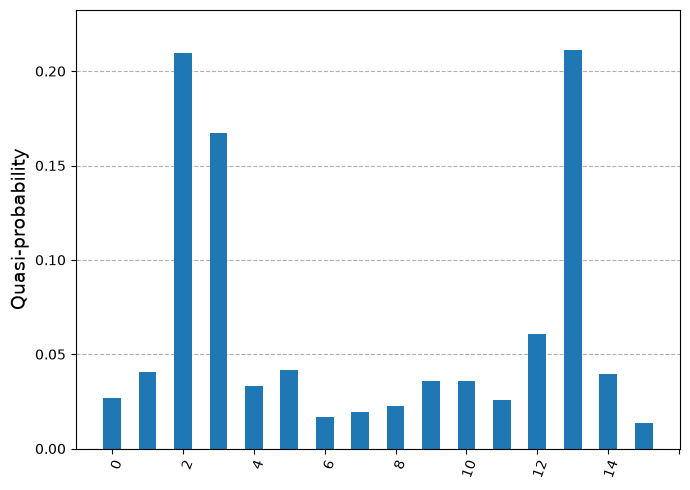


GROVER ITERATION 2

Oracle: 
Oracle output:  {0: np.float64(0.02663550544053922), 1: np.float64(0.04059149251059333), 2: np.float64(0.2093922832752793), 3: np.float64(0.1674321671547036), 4: np.float64(0.03335221780651831), 5: np.float64(0.041789718896547215), 6: np.float64(0.01659776272722846), 7: np.float64(0.0192498869499683), 8: np.float64(0.022625611460569968), 9: np.float64(0.03590248186053748), 10: np.float64(0.03564049665569219), 11: np.float64(0.02601536953197889), 12: np.float64(0.06053072644805165), 13: np.float64(0.2112662878758993), 14: np.float64(0.03959169114827225), 15: np.float64(0.013386300257610837)}


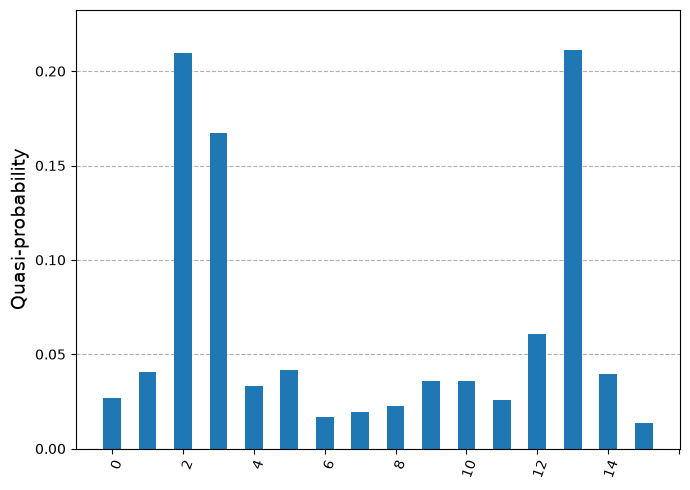


Diffuser: 
Diffuser output:  {0: np.float64(0.022375959114158833), 1: np.float64(0.03814234376211637), 2: np.float64(0.2294622221126819), 3: np.float64(0.18107374521178482), 4: np.float64(0.02895917766188907), 5: np.float64(0.04052803132137371), 6: np.float64(0.009451425974561254), 7: np.float64(0.014221824905146067), 8: np.float64(0.018044887516549778), 9: np.float64(0.03162476819923955), 10: np.float64(0.03218113936261156), 11: np.float64(0.020190798814171042), 12: np.float64(0.060457945185379586), 13: np.float64(0.23012321878701747), 14: np.float64(0.03567427241846412), 15: np.float64(0.007488239652836299)}


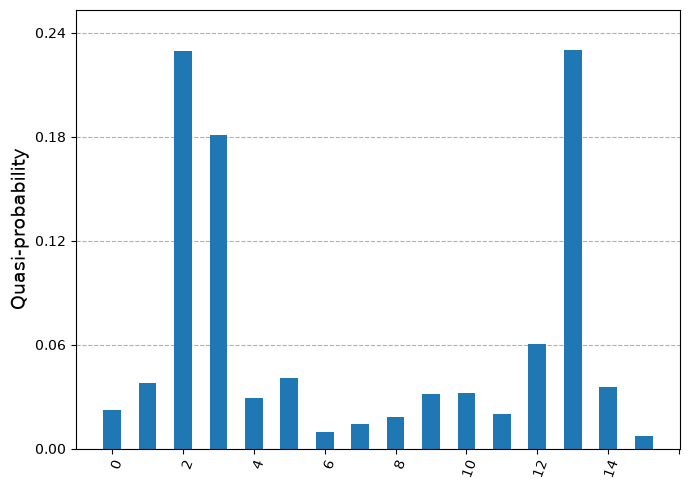


GROVER ITERATION 3

Oracle: 
Oracle output:  {0: np.float64(0.022375959114158826), 1: np.float64(0.03814234376211635), 2: np.float64(0.22946222211268186), 3: np.float64(0.18107374521178474), 4: np.float64(0.028959177661889064), 5: np.float64(0.040528031321373705), 6: np.float64(0.00945142597456125), 7: np.float64(0.014221824905146063), 8: np.float64(0.01804488751654977), 9: np.float64(0.03162476819923954), 10: np.float64(0.03218113936261154), 11: np.float64(0.02019079881417104), 12: np.float64(0.06045794518537957), 13: np.float64(0.23012321878701741), 14: np.float64(0.03567427241846411), 15: np.float64(0.007488239652836294)}


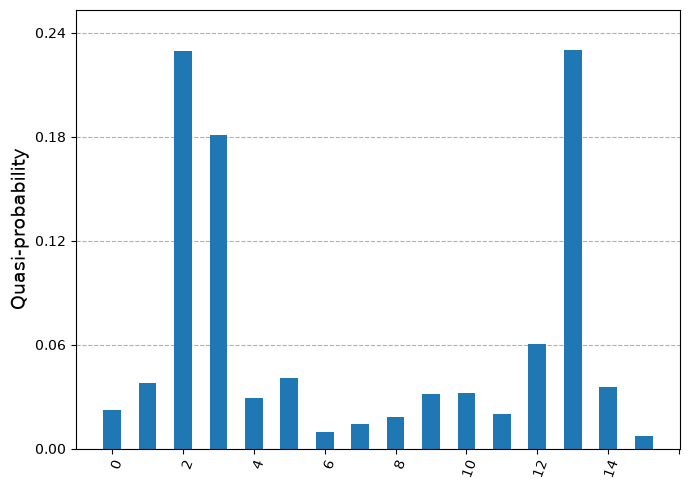


Diffuser: 
Diffuser output:  {0: np.float64(0.054792917344423084), 1: np.float64(0.056781406844343255), 2: np.float64(0.07672145604874975), 3: np.float64(0.07725553731189275), 4: np.float64(0.062392080595787394), 5: np.float64(0.05013001009801625), 6: np.float64(0.06383808649187579), 7: np.float64(0.05248751444037172), 8: np.float64(0.052906143946142584), 9: np.float64(0.06417998757096083), 10: np.float64(0.058508318897866285), 11: np.float64(0.06451825793793388), 12: np.float64(0.06101184153282809), 13: np.float64(0.08661395867850064), 14: np.float64(0.06548749420411688), 15: np.float64(0.05237498805616276)}


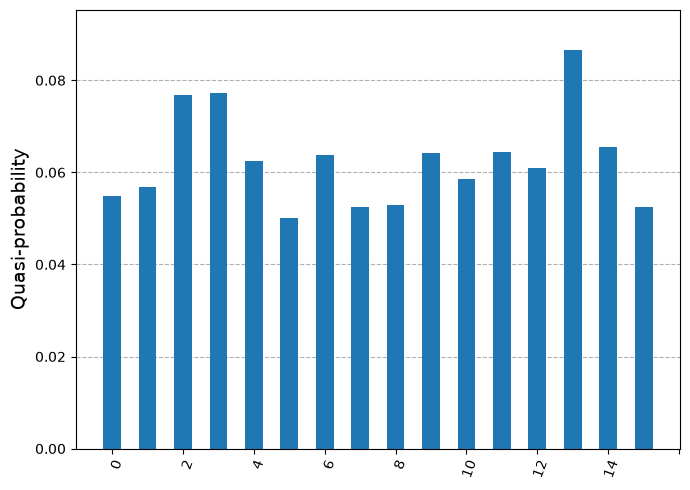


GROVER ITERATION 4

Oracle: 
Oracle output:  {0: np.float64(0.05479291734442307), 1: np.float64(0.05678140684434324), 2: np.float64(0.07672145604874972), 3: np.float64(0.07725553731189273), 4: np.float64(0.06239208059578735), 5: np.float64(0.05013001009801624), 6: np.float64(0.06383808649187576), 7: np.float64(0.052487514440371696), 8: np.float64(0.05290614394614256), 9: np.float64(0.0641799875709608), 10: np.float64(0.05850831889786627), 11: np.float64(0.06451825793793386), 12: np.float64(0.061011841532828064), 13: np.float64(0.08661395867850061), 14: np.float64(0.06548749420411687), 15: np.float64(0.052374988056162745)}


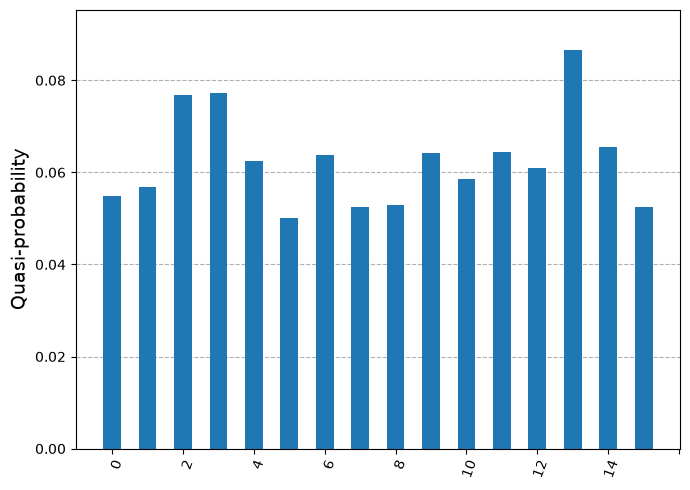


Diffuser: 
Diffuser output:  {0: np.float64(0.06324090126727355), 1: np.float64(0.0616388183305523), 2: np.float64(0.036916625289909674), 3: np.float64(0.05020011326477555), 4: np.float64(0.07110482361361035), 5: np.float64(0.05263232267640274), 6: np.float64(0.07801145928040795), 7: np.float64(0.062459700223323415), 8: np.float64(0.06199112137541327), 9: np.float64(0.072664002878739), 10: np.float64(0.06536928308420341), 11: np.float64(0.0760701641765877), 12: np.float64(0.06115618905010328), 13: np.float64(0.04921489385676975), 14: np.float64(0.0732569344009592), 15: np.float64(0.06407264723093174)}


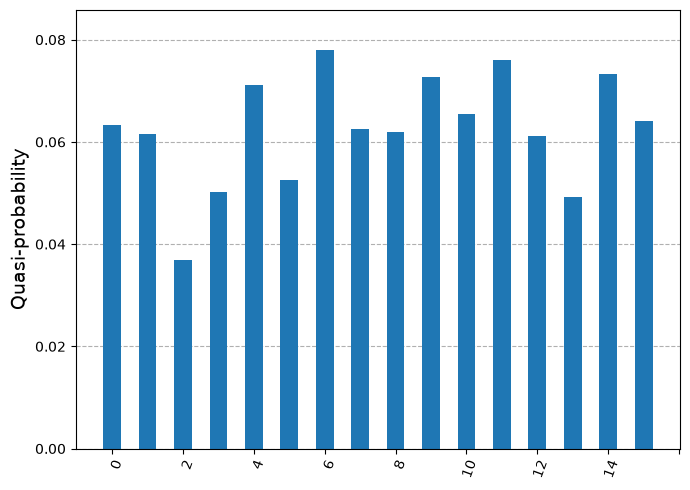


GROVER ITERATION 5

Oracle: 
Oracle output:  {0: np.float64(0.06324090126727352), 1: np.float64(0.06163881833055227), 2: np.float64(0.03691662528990966), 3: np.float64(0.05020011326477553), 4: np.float64(0.07110482361361033), 5: np.float64(0.05263232267640272), 6: np.float64(0.07801145928040791), 7: np.float64(0.0624597002233234), 8: np.float64(0.06199112137541326), 9: np.float64(0.07266400287873898), 10: np.float64(0.06536928308420338), 11: np.float64(0.07607016417658766), 12: np.float64(0.061156189050103255), 13: np.float64(0.04921489385676972), 14: np.float64(0.07325693440095918), 15: np.float64(0.06407264723093171)}


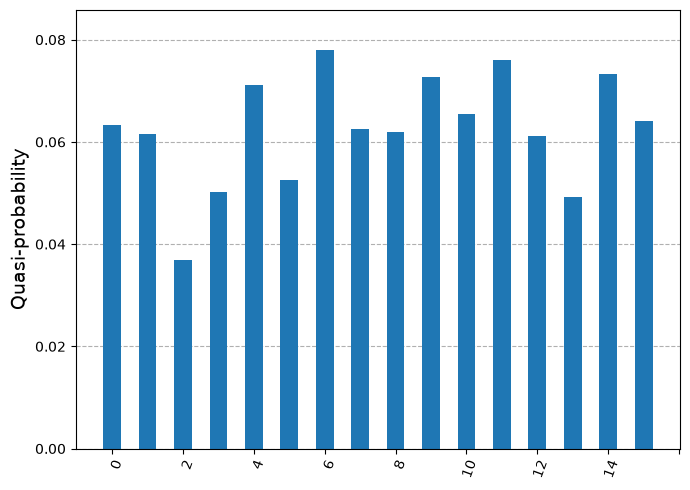


Diffuser: 
Diffuser output:  {0: np.float64(0.03191546597464905), 1: np.float64(0.04362735777493655), 2: np.float64(0.18451440265985652), 3: np.float64(0.15052262133797192), 4: np.float64(0.038797651853038496), 5: np.float64(0.04335365554445474), 6: np.float64(0.02545607136537202), 7: np.float64(0.025482468339047704), 8: np.float64(0.02830369071804638), 9: np.float64(0.04120496188475804), 10: np.float64(0.03992857538082015), 11: np.float64(0.03323527070495035), 12: np.float64(0.06062094314369812), 13: np.float64(0.18789200259378272), 14: np.float64(0.04444756421645975), 15: np.float64(0.02069729650811184)}


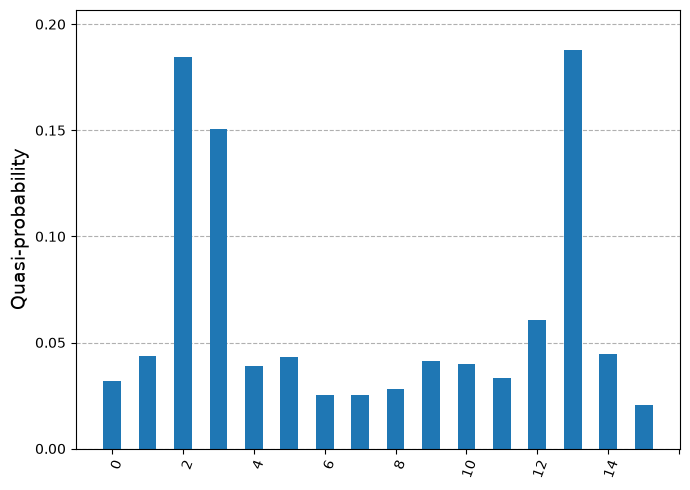


FINAL MEASUREMENT

Index measurement results for (2000) shots:
{'0000': 81, '1001': 82, '0101': 84, '1010': 80, '0100': 88, '1100': 133, '1000': 49, '1110': 103, '0110': 49, '1111': 36, '1101': 366, '0010': 340, '0111': 47, '0001': 96, '0011': 298, '1011': 68}


In [13]:
GS = GroverSearch()

GS.run(dataset=dataset, query=query,
    A_parameters=A_parameters, B_parameters=B_parameters,
    depth_A=depth_A, depth_B=depth_B,
    num_of_iter=5
)

In [14]:
query_index

3

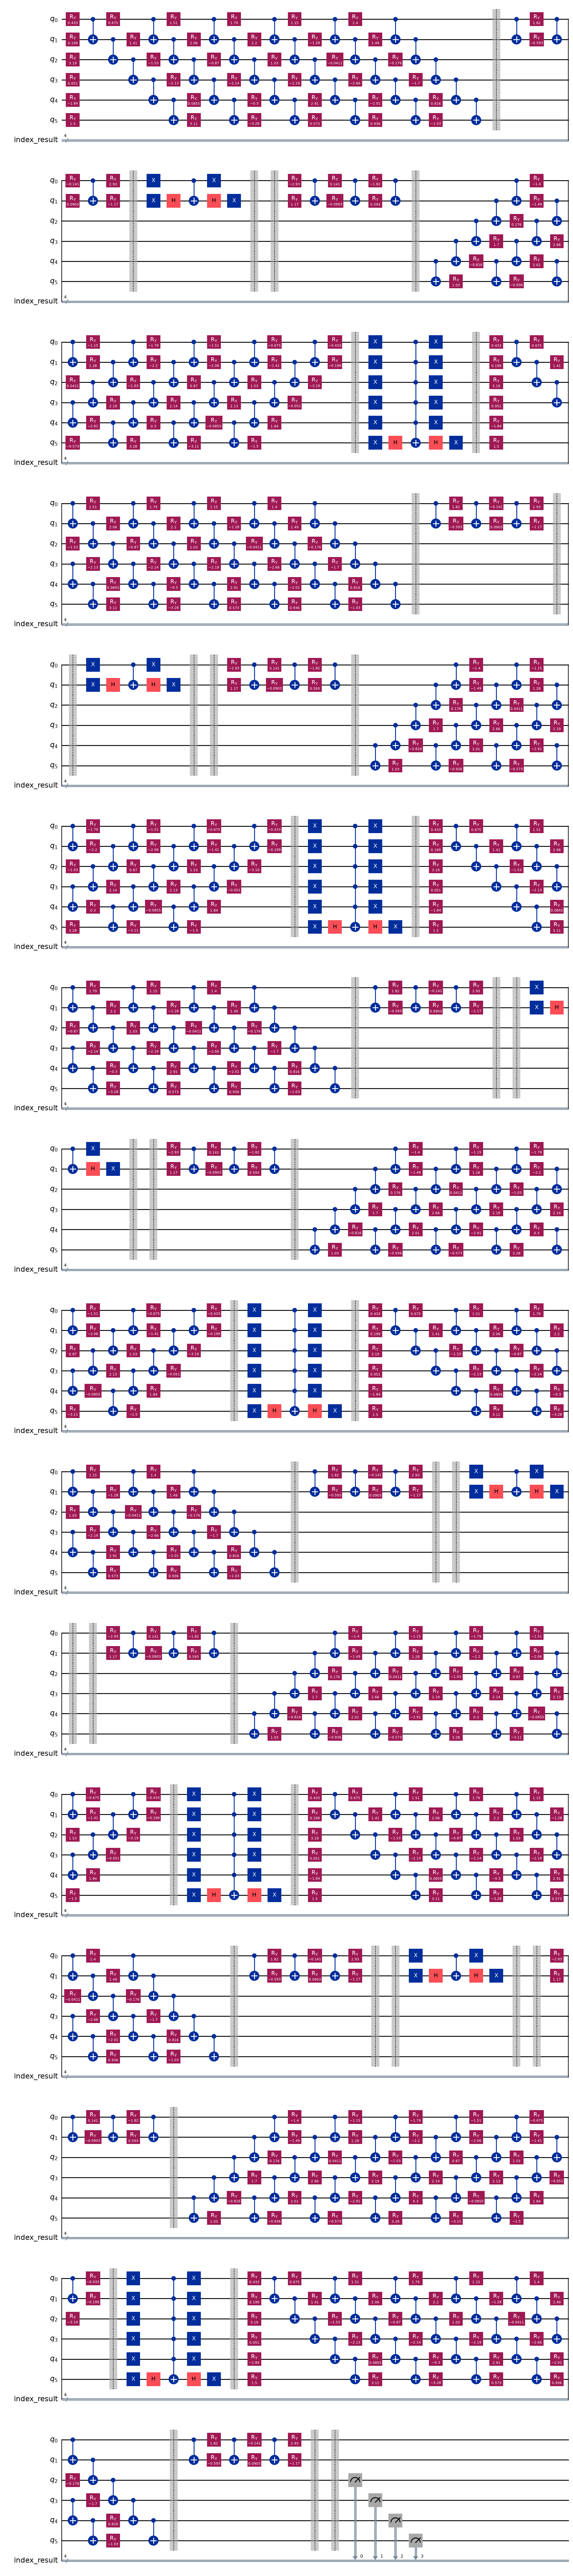

In [15]:
GS.draw_circuit()

In [16]:
GS.analysis()

REGISTER ANALYSIS
Dataset size (N): 16
Index qubits: 4
Data qubits: 2
Total qubits: 6
Classical bits: 4

CIRCUIT ANALYSIS
Circuit width: 10
Circuit size: 939
Circuit depth/layers: 348

OPERATION COUNT
OrderedDict({'ry': 462, 'cx': 368, 'x': 80, 'barrier': 42, 'h': 20, 'mcx': 5, 'measure': 4})
